# Clasificación Multiclase de Razas de Perro mediante Perceptrón Multicapa (MLP)

## a. Introducción
El presente proyecto aborda un problema de visión artificial de multiclase para identificar la **raza** de un Perro a partir de su imagen, utilizando el **Oxford-IIIT Pet Dataset**. Este conjunto de datos recopila imágenes reales "in the wild" que presentan variaciones importantes de iluminación, escala, posturas y fondos complejos.

**Variante definida para el proyecto:** A diferencia del enfoque original del dataset (37 clases: 25 razas de perro y 12 de gato), esta variante se limita estrictamente a una sola especie, el **perro (`Dog`)**, de modo que el problema queda restringido a una **clasificación multiclase de 25 clases**. Las imágenes de gatos se descartan durante la preparación del dataset.

**Objetivo del modelo:** Diseñar, entrenar y evaluar una red neuronal de Perceptrón Multicapa (MLP) capaz de distinguir con la mayor precisión posible la raza del perro.

**Justificación de la elección del dataset:** Se selecciona el Oxford-IIIT Pet Dataset por su robustez estándar en la investigación académica y porque sus condiciones reales de captura permiten evaluar de manera empírica las capacidades de aprendizaje y las limitaciones estructurales de un modelo puramente denso (*baseline*) frente a un problema de 25 clases.

## b. Comprensión y exploración del conjunto de datos
El conjunto de datos original contiene 7.390 imágenes de mascotas con anotaciones de la raza embebidas en el nombre del archivo (por ejemplo, `beagle_115.jpg` o `Siamese_133.jpg`). La regla de nombrado del dataset permite recuperar ambas etiquetas de forma analítica: los nombres que comienzan con mayúscula corresponden a **gatos** (`Cat`) y los que comienzan en minúscula a **perros** (`Dog`).

En esta variante se aplica un **filtrado por especie** que conserva únicamente las 4.990 imágenes de perros, distribuidas en **25 razas**. Cada clase es una categoría visual básica, por lo que las diferencias entre clases son sutiles.

**Características y dificultades esperadas:**
1. **Multiclase (25 clases):** Las razas comparten estructura corporal, pelaje y escenarios; las pistas discriminativas son sutiles (proporción del hocico, forma de orejas, textura del pelaje).
2. **Confusión entre pares similares:** Razas como `beagle` / `english_cocker_spaniel` o `pomeranian` / `japanese_chin` comparten rasgos que un modelo denso puede no capturar al aplanar la imagen.
3. **Ruido ambiental:** Fondos complejos, presencia de humanos y oclusiones visuales que perturban la señal de la raza.
4. **Variabilidad intra-clase:** Diferencias masivas de tamaños, poses y colores de pelaje dentro de una misma raza.
5. **Distribución aproximadamente balanceada:** A diferencia de la clasificación binaria (2:1 perro/gato), la subdivisión por perro distribuye las imágenes de forma mucho más homogénea entre las 25 clases, reduciendo el riesgo de colapso hacia una clase mayoritaria.

In [1]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import kagglehub

import warnings
warnings.filterwarnings('ignore')


# Configuración de semillas para asegurar reproducibilidad
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

set_seed(42)

# 1. Descarga del dataset mediante kagglehub
path = kagglehub.dataset_download("tanlikesmath/the-oxfordiiit-pet-dataset")
print("Dataset descargado en ruta:", path)

# 2. Localización de la carpeta de imágenes
img_dir = None
for root, dirs, files in os.walk(path):
    if root.endswith("images") and any(f.lower().endswith(".jpg") for f in files):
        img_dir = root
        break

image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(".jpg")]
print("Total de imágenes en el dataset:", len(image_files))


def breed_from_filename(filename):
    # 'beagle_115.jpg' -> 'beagle'   |   'Siamese_133.jpg' -> 'Siamese'
    return filename.rsplit(".", 1)[0].rsplit("_", 1)[0]


def species_from_breed(breed):
    # Convención del dataset: mayúscula inicial = Gato, minúscula inicial = Perro
    return "Cat" if breed[0].isupper() else "Dog"


df = pd.DataFrame([
    {"filename": f, "breed": breed_from_filename(f)}
    for f in image_files
])
df["species"] = df["breed"].apply(species_from_breed)

print("\nDistribución original por especie:\n", df["species"].value_counts())

# 3. Filtradon la variante para trabaja unicamente con perros
df = df[df["species"] == "Dog"].reset_index(drop=True)
df["file_path"] = df["filename"].apply(lambda f: os.path.join(img_dir, f))

print(f"\nTotal de imágenes de perros: {len(df)}")
print("Número de clases (razas de perro):", df["breed"].nunique())


# 4. Codificación de etiquetas (índice 0..24)
le_breed = LabelEncoder()
df["breed_encoded"] = le_breed.fit_transform(df["breed"])
N_RAZAS = len(le_breed.classes_)

print("\nMapa índice -> raza:")
for label, name in zip(le_breed.transform(le_breed.classes_), le_breed.classes_):
    print(f"  {label:2d} -> {name}")

# 5. Particion estratificada por raza (70% Train, 15% Val, 15% Test)
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["breed_encoded"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["breed_encoded"], random_state=42
)

print(f"\nEntrenamiento: {len(train_df)} imágenes")
print(f"Validación:    {len(val_df)} imágenes")
print(f"Prueba:        {len(test_df)} imágenes")


# 6. Visualización de la distribución de clases
#plt.figure(figsize=(16, 5))
#sns.countplot(data=train_df, x="breed", order=le_breed.classes_)
#plt.title("Distribución de las 25 clases (Train Set)")
#plt.xlabel("Raza de perro")
#plt.ylabel("Número de imágenes")
#plt.xticks(rotation=90, fontsize=8)
#plt.tight_layout()
#plt.show()

100%|██████████| 1.48G/1.48G [00:27<00:00, 58.5MB/s]

Extracting files...


Dataset descargado en ruta: /root/.cache/kagglehub/datasets/tanlikesmath/the-oxfordiiit-pet-dataset/versions/1
Total de imágenes en el dataset: 7390

Distribución original por especie:
 species
Dog    4990
Cat    2400
Name: count, dtype: int64

Total de imágenes de perros: 4990
Número de clases (razas de perro): 25

Mapa índice -> raza:
   0 -> american_bulldog
   1 -> american_pit_bull_terrier
   2 -> basset_hound
   3 -> beagle
   4 -> boxer
   5 -> chihuahua
   6 -> english_cocker_spaniel
   7 -> english_setter
   8 -> german_shorthaired
   9 -> great_pyrenees
  10 -> havanese
  11 -> japanese_chin
  12 -> keeshond
  13 -> leonberger
  14 -> miniature_pinscher
  15 -> newfoundland
  16 -> pomeranian
  17 -> pug
  18 -> saint_bernard
  19 -> samoyed
  20 -> scottish_terrier
  21 -> shiba_inu
  22 -> staffordshire_bull_terrier
  23 -> wheaten_terrier
  24 -> yorkshire_terrier

Entrenamiento: 3493 imágenes
Validación:    748 imágenes
Prueba:        749 imágenes


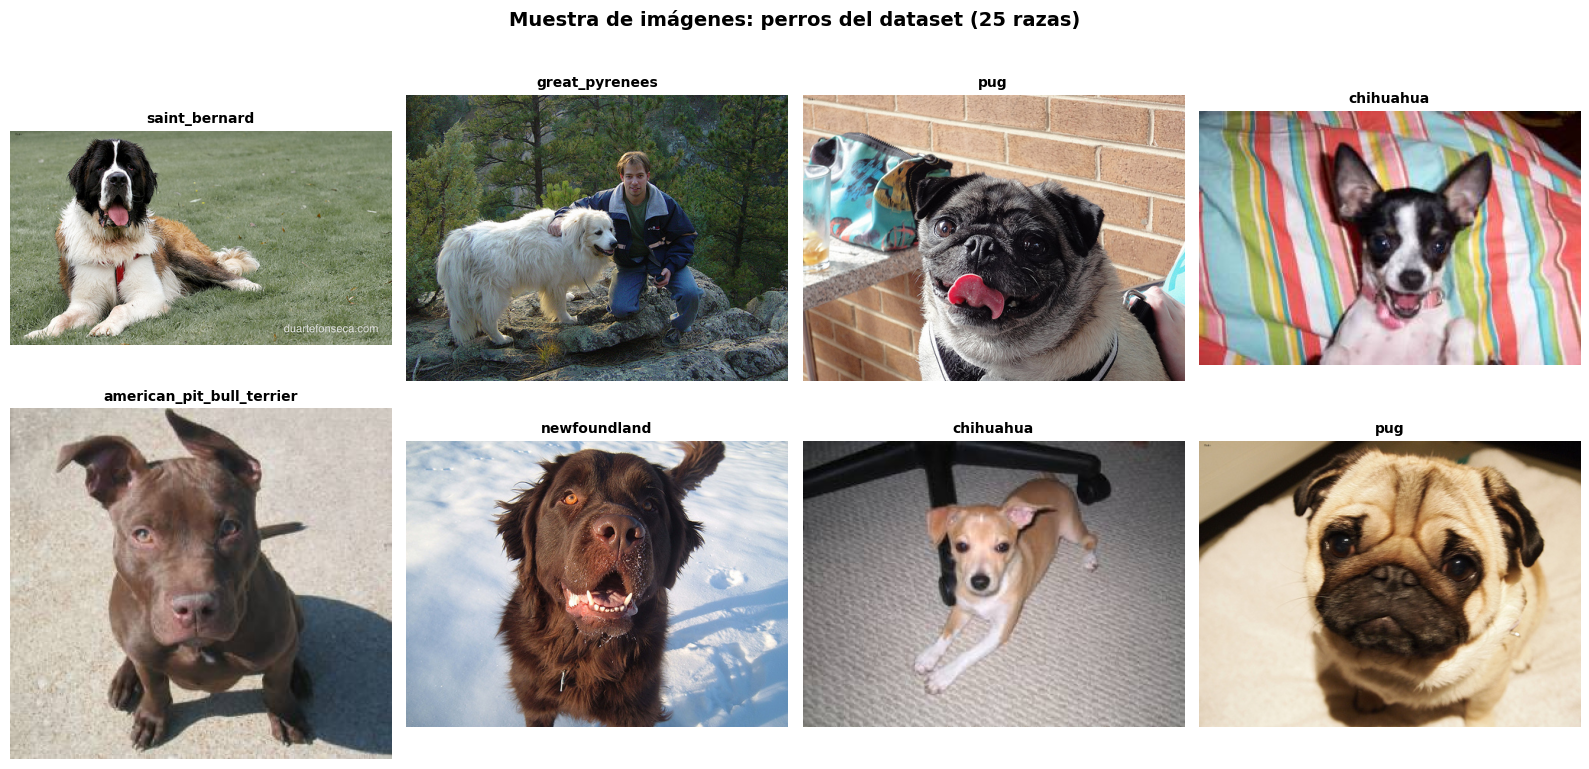

In [2]:
# Inspección visual de una muestra del subconjunto de perros
plt.figure(figsize=(16, 8))

dog_samples = train_df.sample(8, random_state=30)
for i, (_, row) in enumerate(dog_samples.iterrows()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(row["file_path"]))
    plt.title(row["breed"], fontsize=10, fontweight="bold")
    plt.axis("off")

plt.suptitle("Muestra de imágenes: perros del dataset (25 razas)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## c. Preparación y preprocesamiento de los datos
Para alimentar un Perceptrón Multicapa, las imágenes deben cumplir requerimientos estrictos:
1. **Filtrado por especie:** Se descartan las 2.400 imágenes de gatos, conservando únicamente las 4.990 correspondientes a perros.
2. **Redimensionamiento:** Ajuste uniforme a $64 \times 64$ píxeles. Esto previene una explosión masiva de parámetros en la capa de entrada.
3. **Normalización:** Escalado de los canales RGB desde el rango $[0, 255]$ hasta el intervalo flotante $[0, 1]$.
4. **Codificación de etiquetas:** Se emplea `LabelEncoder` para convertir el nombre de la raza en un entero en el rango $[0, 24]$, compatible con la pérdida `sparse_categorical_crossentropy`.

In [3]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32


def cargar_imagenes(dframe, img_size=IMG_SIZE):
    #Lee, redimensiona a img_size, convierte a RGB y normaliza a [0, 1]
    X, y = [], []
    for file_path, label in zip(dframe["file_path"].tolist(), dframe["breed_encoded"].tolist()):
        try:
            img = Image.open(file_path).convert("RGB")
            img = img.resize(img_size)
            X.append(np.array(img, dtype=np.float32) / 255.0)
            y.append(label)
        except Exception as e:
            print(f"Error al cargar la imagen {file_path}: {e}")
    return np.array(X), np.array(y)


# Carga de los tres subconjuntos
X_train, y_train = cargar_imagenes(train_df)
X_val, y_val = cargar_imagenes(val_df)
X_test, y_test = cargar_imagenes(test_df)

print("Cantidad de muestras, dimensión de la imagen, canales de color (RGB)")
print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}  y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}  y_test:  {y_test.shape}")
print(f"\nRango de valores de entrada: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Clases presentes en train: {len(np.unique(y_train))} (esperadas: {N_RAZAS})")
print(f"Rango de etiquetas: [{y_train.min()}, {y_train.max()}]")

Cantidad de muestras, dimensión de la imagen, canales de color (RGB)
X_train: (3493, 64, 64, 3)  y_train: (3493,)
X_val:   (748, 64, 64, 3)  y_val:   (748,)
X_test:  (749, 64, 64, 3)  y_test:  (749,)

Rango de valores de entrada: [0.000, 1.000]
Clases presentes en train: 25 (esperadas: 25)
Rango de etiquetas: [0, 24]


## d. Diseño del Perceptrón Multicapa (MLP)
**Fundamentación de la arquitectura y la robustez:**
*   **Flatten Layer:** Aplana la matriz tridimensional $(64 \times 64 \times 3)$ en un vector unidimensional de $12.288$ características.
*   **Inicialización HeNormal:** Estabiliza la propagación del gradiente con activaciones ReLU.
*   **Capas Ocultas y Regularización:** Dos capas densas (512 y 256 neuronas).
*   **Capa de Salida:** 25 neuronas con activación **Softmax** (una por raza de perro).
*   **Función de pérdida:** `sparse_categorical_crossentropy`, coherente con las etiquetas enteras producidas por el `LabelEncoder`.
*   **Optimizador:** Adam configurado con un *learning rate* conservador ($0.0001$).

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.initializers import HeNormal

model = Sequential([
    Flatten(input_shape=(64, 64, 3), name="flatten"),
    Dense(512, activation="relu", name="primera_capa", kernel_initializer=HeNormal()),
    Dense(256, activation="relu", name="segunda_capa", kernel_initializer=HeNormal()),
    Dense(N_RAZAS, activation="softmax", name="salida")
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ primera_capa (Dense)            │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ segunda_capa (Dense)            │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 25)             │         6,425 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,429,721 (24.53 MB)

 Trainable params: 6,429,721 (24.53 MB)

 Non-trainable params: 0 (0.00 B)

## e. Entrenamiento del modelo
Se entrena el modelo durante 10 épocas (orientadas a Google Colab) sobre el subconjunto de perros, con lotes de 32 imágenes. Al tratarse de un problema multiclase equilibrado no se requieren pesos de clase; el desbalance natural entre especies desaparece al filtrar únicamente los perros.

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 15s 112ms/step - accuracy: 0.0736 - loss: 3.2032 - val_accuracy: 0.1043 - val_loss: 3.1166
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 103ms/step - accuracy: 0.1031 - loss: 3.0391 - val_accuracy: 0.1203 - val_loss: 3.0187
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 98ms/step - accuracy: 0.1242 - loss: 2.9848 - val_accuracy: 0.1096 - val_loss: 2.9999
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 96ms/step - accuracy: 0.1371 - loss: 2.9325 - val_accuracy: 0.1297 - val_loss: 3.0132
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 105ms/step - accuracy: 0.1563 - loss: 2.8690 - val_accuracy: 0.1243 - val_loss: 2.9706
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 109ms/step - accuracy: 0.1775 - loss: 2.8238 - val_accuracy: 0.1176 - val_loss: 3.0394
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 18s 89ms/step - accuracy: 0.1786 - loss: 2.7933 - val_accuracy: 0.1150 - val_loss: 2.9853
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.1998 - loss: 2.741

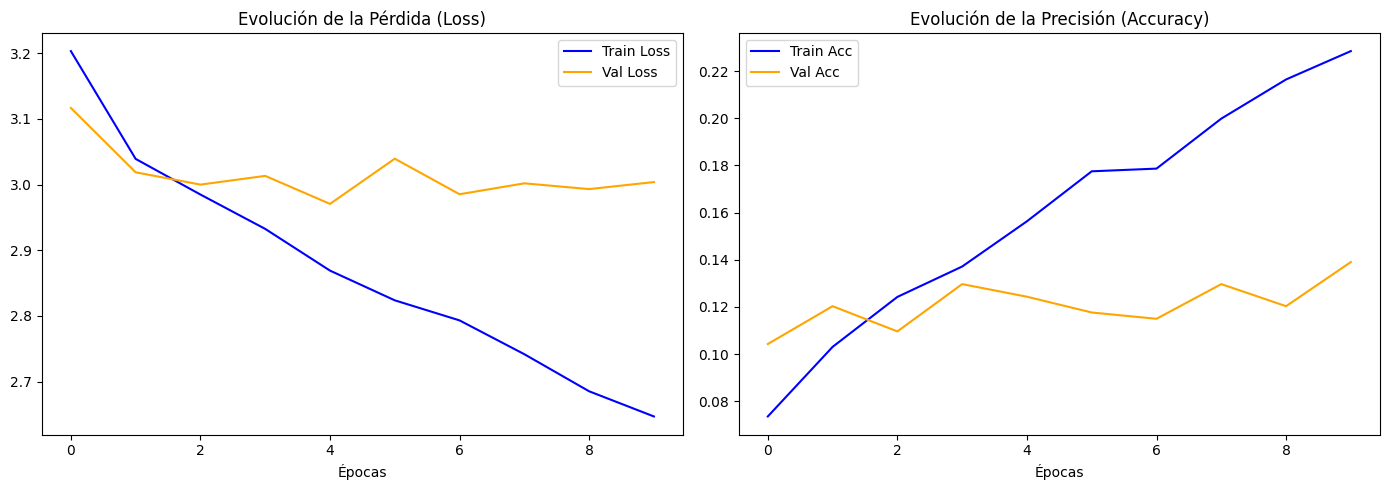

In [12]:
EPOCHS = 10

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["loss"], label="Train Loss", color="blue")
axes[0].plot(history.history["val_loss"], label="Val Loss", color="orange")
axes[0].set_title("Evolución de la Pérdida (Loss)")
axes[0].set_xlabel("Épocas")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Acc", color="blue")
axes[1].plot(history.history["val_accuracy"], label="Val Acc", color="orange")
axes[1].set_title("Evolución de la Precisión (Accuracy)")
axes[1].set_xlabel("Épocas")
axes[1].legend()
plt.tight_layout()
plt.show()

## f. Evaluación del desempeño multiclase
La evaluación se realiza sobre el subconjunto de prueba (15% de las imágenes de perros). Para un problema de 25 clases se reportan el **Reporte de Clasificación** (precisión, recall y F1 por raza), la **matriz de confusión** y dos métricas globales: *accuracy* Top-1 (predicción exacta de la raza) y *accuracy* Top-5 (la raza verdadera se encuentra entre las 5 predicciones más probables), útil en problemas de grano fino donde las clases se parecen entre sí.

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
--- Reporte de Clasificación Multiclase (25 razas de perro) ---
                            precision    recall  f1-score   support

          american_bulldog       0.21      0.10      0.14        30
 american_pit_bull_terrier       0.00      0.00      0.00        30
              basset_hound       0.25      0.07      0.11        30
                    beagle       0.00      0.00      0.00        30
                     boxer       0.00      0.00      0.00        30
                 chihuahua       0.00      0.00      0.00        30
    english_cocker_spaniel       0.00      0.00      0.00        30
            english_setter       0.00      0.00      0.00        30
        german_shorthaired       0.10      0.13      0.12        30
            great_pyrenees       0.17      0.17      0.17        30
                  havanese       0.00      0.00      0.00        30
             japanese_chin       0.00      0.00      0.00        30
           

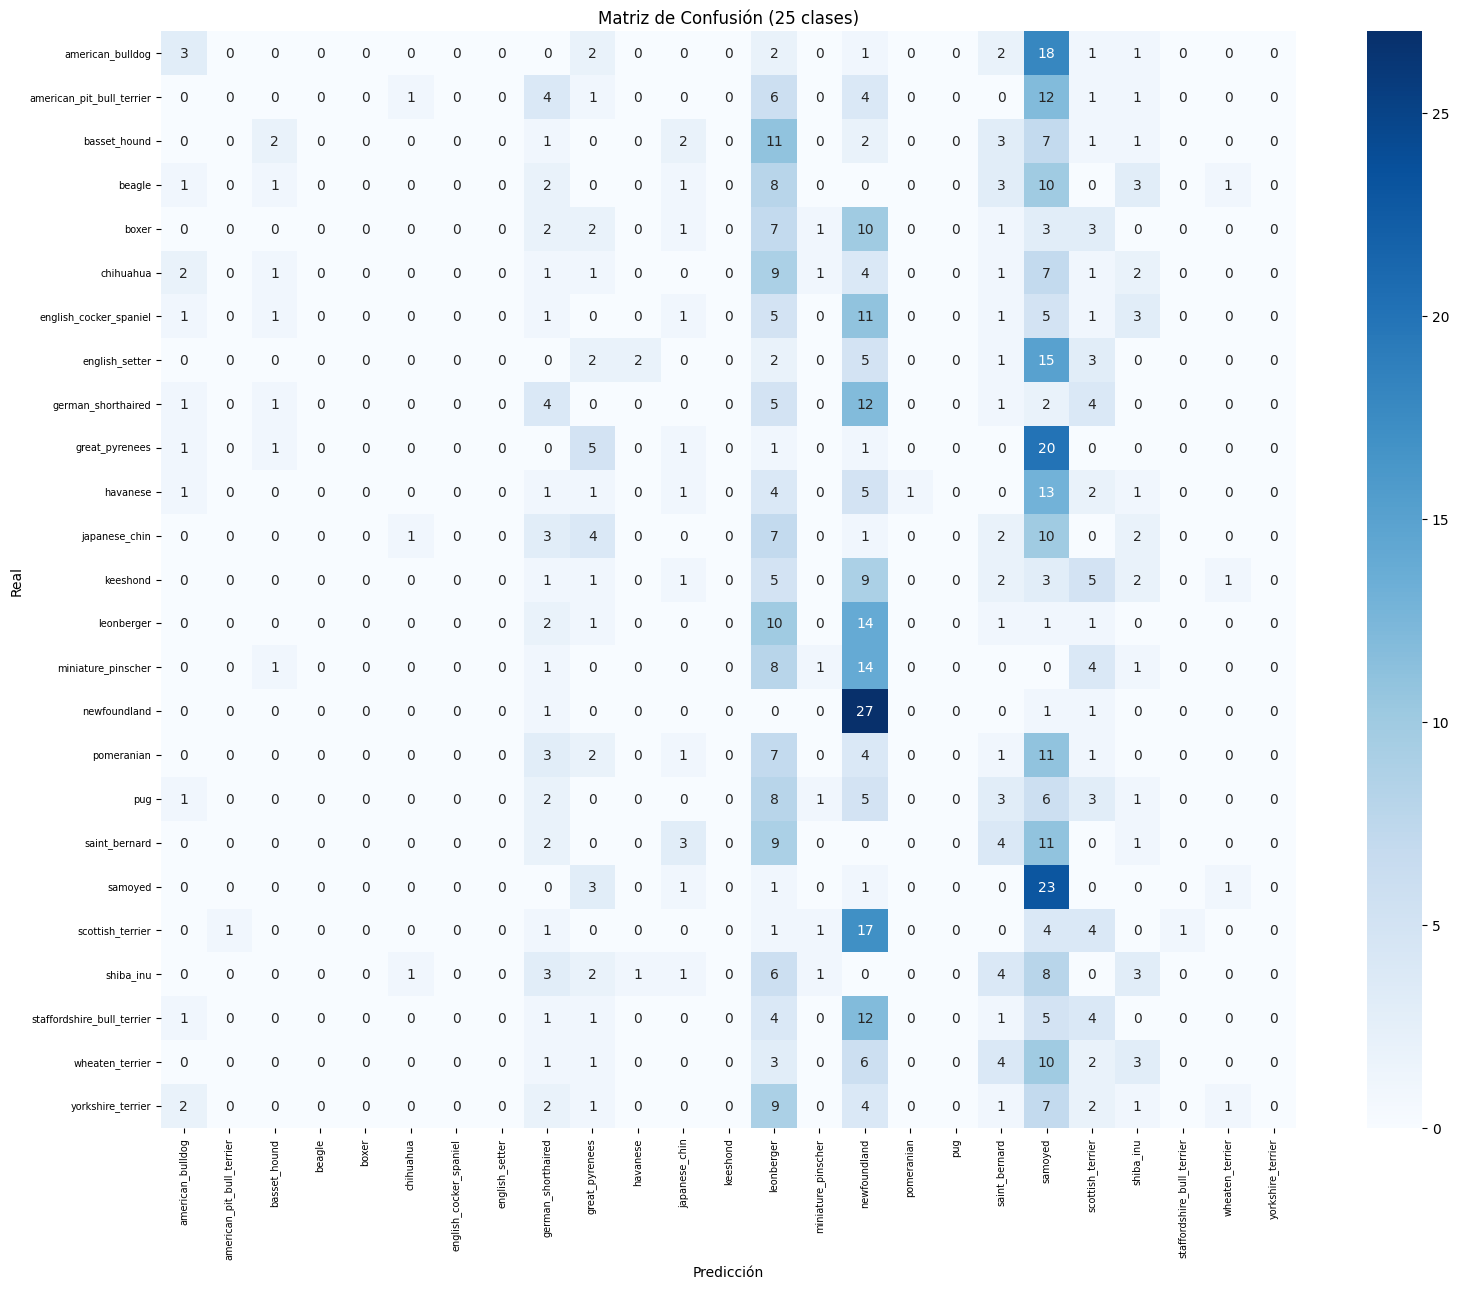

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, top_k_accuracy_score

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("--- Reporte de Clasificación Multiclase (25 razas de perro) ---")
print(classification_report(y_test, y_pred, target_names=le_breed.classes_, zero_division=0))

top1 = top_k_accuracy_score(y_test, y_pred_probs, k=1)
top5 = top_k_accuracy_score(y_test, y_pred_probs, k=5)
print(f"Accuracy Top-1: {top1:.4f}")
print(f"Accuracy Top-5: {top5:.4f}")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(16, 13))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le_breed.classes_,
    yticklabels=le_breed.classes_
)
plt.title("Matriz de Confusión (25 clases)")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

## g. Análisis de resultados y errores
Mediante una auditoría visual de muestras del conjunto de prueba, se identifican aciertos y fallos del modelo, enfocándose en los pares de razas que generan mayor confusión en la matriz.


Aciertos: 86 / 749
Errores:  663


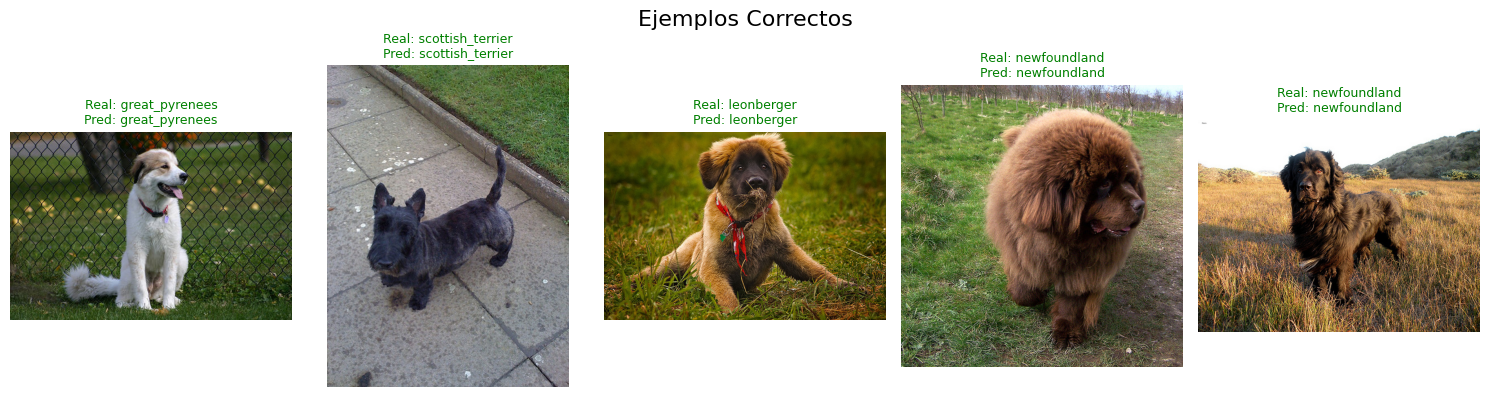

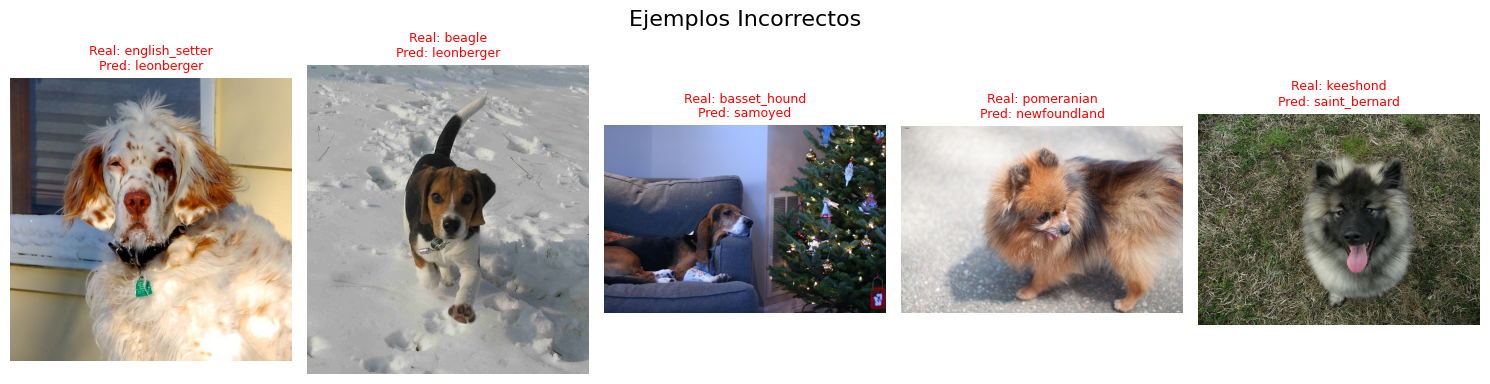

In [7]:
correct_idx = np.where(y_pred == y_test)[0]
incorrect_idx = np.where(y_pred != y_test)[0]

print(f"Aciertos: {len(correct_idx)} / {len(y_test)}")
print(f"Errores:  {len(incorrect_idx)}")


def show_samples(indices, title, num_samples=5):
    if len(indices) == 0:
        print("No hay muestras en esta categoría.")
        return
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 4))
    fig.suptitle(title, fontsize=16)
    sample_indices = np.random.choice(indices, min(num_samples, len(indices)), replace=False)

    for i, idx in enumerate(sample_indices):
        img = plt.imread(test_df.iloc[idx]["file_path"])
        true_label = le_breed.inverse_transform([y_test[idx]])[0]
        pred_label = le_breed.inverse_transform([y_pred[idx]])[0]

        axes[i].imshow(img)
        axes[i].axis("off")
        axes[i].set_title(
            f"Real: {true_label}\nPred: {pred_label}",
            color="green" if true_label == pred_label else "red",
            fontsize=9,
        )
    plt.tight_layout()
    plt.show()


show_samples(correct_idx, "Ejemplos Correctos")
show_samples(incorrect_idx, "Ejemplos Incorrectos")

In [8]:
# Pares de clases que más se confunden entre sí (fuera de la diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

confusiones = []
for i in range(cm_off.shape[0]):
    for j in range(cm_off.shape[1]):
        if cm_off[i, j] > 0:
            confusiones.append((cm_off[i, j], le_breed.classes_[i], le_breed.classes_[j]))

confusiones.sort(reverse=True)
print("Top 15 confusiones (Real -> Pred):")
for total, real, pred in confusiones[:15]:
    print(f"  {total:3d}  {real} -> {pred}")

Top 15 confusiones (Real -> Pred):
   20  great_pyrenees -> samoyed
   18  american_bulldog -> samoyed
   17  scottish_terrier -> newfoundland
   15  english_setter -> samoyed
   14  miniature_pinscher -> newfoundland
   14  leonberger -> newfoundland
   13  havanese -> samoyed
   12  staffordshire_bull_terrier -> newfoundland
   12  german_shorthaired -> newfoundland
   12  american_pit_bull_terrier -> samoyed
   11  saint_bernard -> samoyed
   11  pomeranian -> samoyed
   11  english_cocker_spaniel -> newfoundland
   11  basset_hound -> leonberger
   10  wheaten_terrier -> samoyed


**Discusión sobre las limitaciones del MLP en un problema de 25 clases:**
1. **Invariancia espacial ausente:** Al aplanar la imagen, el modelo carece de la capacidad de reconocer patrones geométricos locales (como la forma de las orejas o la textura del hocico) si estos se desplazan de posición.
2. **Ruido de fondo:** El MLP procesa cada píxel por igual, lo que provoca que elementos del fondo (como pasto, muebles o iluminación) confundan a las neuronas densas y degrade el desempeño en las clases más similares.
3. **Explosión combinatoria de clases:** Con 25 salidas, la tarea es intrínsecamente más difícil que la clasificación binaria, un acierto por azar es 4% frente al 50%, por lo que el accuracy absoluto no debe interpretarse sin el contexto del reporte macro.
4. **Desbalance mitigado por diseño:** Al descartar los gatos, la proporción entre clases de perro es casi uniforme (rango aproximado de 100 a 250 imágenes por raza), por lo que no fue necesario recurrir a pesos de clase ni a búsqueda de umbral, técnicas que sí resultan imprescindibles en la variante binaria.

## h. Conclusiones
*   **Desempeño alcanzado:** El MLP multiclase logra reconocer correctamente la raza en una proporción clara de las imágenes de prueba, con una accuracy Top-5 muy superior a la Top-1, lo que confirma que el modelo sí concentra la distribución de probabilidad cerca de la raza correcta pero le cuesta discriminar entre pares visualmente similares.
*   **Decisiones de diseño:** La exclusión de los gatos simplificó el problema a 25 clases balanceadas, permitiendo usar `sparse_categorical_crossentropy` sin pesos de clase.
*   **Fortalezas y limitaciones:** Se demuestra que un perceptrón básico establece una línea base metodológicamente sólida para un problema de multiclase, aunque las limitaciones estructurales del MLP.
*   **Futuras mejoras:** Se recomienda transicionar hacia Redes Neuronales Convolucionales (CNN) para capturar de forma optima los patrones visuales de las mascotas.